# Fase 8 — Selección final del modelo y política de decisión

Solo protocolo v3 y dos modelos iniciales. Se revisa fase 7.1, manifiesto y seguimiento, sin regenerarlos. Se fija previamente capacidad académica de 20% por mes de llegada y sensibilidad 10%/30% (seleccion_8_plan_previo.md). No se optimizan parámetros, predictores o capacidad por métricas y no se abre prueba.

## 1. Protocolo y entrenamiento permitido

Train julio 2015–junio 2016 (49.157); validación septiembre–diciembre 2016 (19.911). Embargos julio–agosto 2016 y enero–febrero 2017. Prueba marzo–agosto 2017 reservada. Cierres proxy de seguimiento antes de 01/09/2016 y 01/03/2017, auditados para todo el bloque, sin selección por resultado. Es retrospectivo por llegada, no simulación al alta. No hay snapshots o cierre PMS acreditados y parte de la prueba ampliada tuvo exposición bajo v2.

Las dos fábricas iniciales se ajustan solo con train v3 y sus scores se contrastan con fase 7.1. Las etiquetas/features de prueba no se cargan; solo se verifica el manifiesto con metadatos. No se utiliza run_v3 ni se consultan scores v2.

### Contexto metodológico

La elección utiliza solo train y validación v3. Se comparan logística y XGBoost iniciales, sin nuevas búsquedas. A la capacidad mensual hipotética del 20%, logística detectó 32 cancelaciones más con el mismo volumen de prioridades y menor complejidad. Es una ventaja pequeña y descriptiva. La decisión se cerró antes de prueba.

**Qué se hace y por qué.** Cargar la comparación de los dos candidatos y la especificación congelada de fase 8.



In [1]:
# Cargar la comparación de los dos candidatos y la especificación congelada de fase 8.
from pathlib import Path
import sys
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/"src").is_dir(): ROOT=ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.final_selection import run_selection
tables,specification,verification=run_selection(ROOT)
display(tables["metricas"].round(6))

Ajuste con train v3: regresion_logistica


Ajuste con train v3: xgboost


,modelo,accuracy,precision,recall,f1,roc_auc,average_precision,tn,fp,fn,tp,fit_seconds,predict_seconds
0,regresion_logistica,0.756567,0.772463,0.509908,0.614307,0.794590,0.762161,11204,1137,3710,3860,0.263971,0.021169
1,xgboost,0.758877,0.830508,0.459577,0.591717,0.830592,0.790062,11631,710,4091,3479,0.436060,0.035632


## 2. Umbrales y capacidad son políticas diferentes

Umbrales fijos 0,1–0,9 generan distintos volúmenes. La política seleccionada usa k=floor(n_mes*20/100), ordenando por score descendente dentro de cada mes y ambos hoteles juntos. Empates exactos: SHA256(42|ID) ascendente, después ID numérico ascendente, sin usar etiqueta ni redondear scores.

Se requiere conocer el lote mensual completo: no es una cola online ni se acredita contacto antes de la cancelación. La capacidad es ilustrativa; no se impone una cuota por hotel. 10% y 30% muestran sensibilidad, sin cambiar el 20% prefijado para mejorar métricas.

**Qué se hace y por qué.** Contrastar umbrales y capacidad igual, distinguiendo ranking y clasificación fija.

Comparar igual número de alertas mide priorización a capacidad limitada. Un umbral fijo puede alertar volúmenes distintos y no ofrece esa misma comparación.



,modelo,umbral,precision,recall,f1,fp,fn,tp,tn,alertas,porcentaje_alertado
0,regresion_logistica,0.1,0.47861,0.89102,0.62272,7348,825,6745,4993,14093,70.77997
1,regresion_logistica,0.2,0.56251,0.76262,0.64745,4490,1797,5773,7851,10263,51.54437
2,regresion_logistica,0.3,0.63732,0.65878,0.64787,2838,2583,4987,9503,7825,39.29988
3,regresion_logistica,0.4,0.70511,0.58151,0.63737,1841,3168,4402,10500,6243,31.35453
4,regresion_logistica,0.5,0.77246,0.50991,0.61431,1137,3710,3860,11204,4997,25.09668
5,regresion_logistica,0.6,0.82731,0.45694,0.58872,722,4111,3459,11619,4181,20.99844
6,regresion_logistica,0.7,0.88509,0.40700,0.55760,400,4489,3081,11941,3481,17.48280
7,regresion_logistica,0.8,0.92732,0.34386,0.50169,204,4967,2603,12137,2807,14.09773
8,regresion_logistica,0.9,0.96613,0.27503,0.42817,73,5488,2082,12268,2155,10.82316
9,xgboost,0.1,0.53203,0.88217,0.66375,5874,892,6678,6467,12552,63.04053


,modelo,capacidad_pct,precision,recall,f1,fp,fn,tp,tn,alertas,porcentaje_alertado
0,regresion_logistica,10,0.96533,0.25376,0.40188,69,5649,1921,12272,1990,9.99448
1,regresion_logistica,20,0.85603,0.45007,0.58996,573,4163,3407,11768,3980,19.98895
2,regresion_logistica,30,0.71885,0.56711,0.63403,1679,3277,4293,10662,5972,29.99347
3,xgboost,10,0.96533,0.25376,0.40188,69,5649,1921,12272,1990,9.99448
4,xgboost,20,0.84799,0.44584,0.58442,605,4195,3375,11736,3980,19.98895
5,xgboost,30,0.75435,0.59511,0.66534,1467,3065,4505,10874,5972,29.99347


,mes_llegada,n,k,capacidad_pct,porcentaje_alertado,score_min_alertado,score_max_no_alertado,empate_total_en_corte,empate_alertado_en_corte,modelo
4,2016-09,5394,1078,20,19.985169,0.727847,0.727847,11,10,regresion_logistica
5,2016-10,6203,1240,20,19.990327,0.570409,0.568892,4,4,regresion_logistica
6,2016-11,4454,890,20,19.982039,0.641885,0.641885,12,10,regresion_logistica
7,2016-12,3860,772,20,20.000000,0.571607,0.571233,1,1,regresion_logistica
16,2016-09,5394,1078,20,19.985169,0.716751,0.716751,2,1,xgboost
17,2016-10,6203,1240,20,19.990327,0.461578,0.461578,14,7,xgboost
18,2016-11,4454,890,20,19.982039,0.642283,0.641550,1,1,xgboost
19,2016-12,3860,772,20,20.000000,0.450367,0.449897,1,1,xgboost


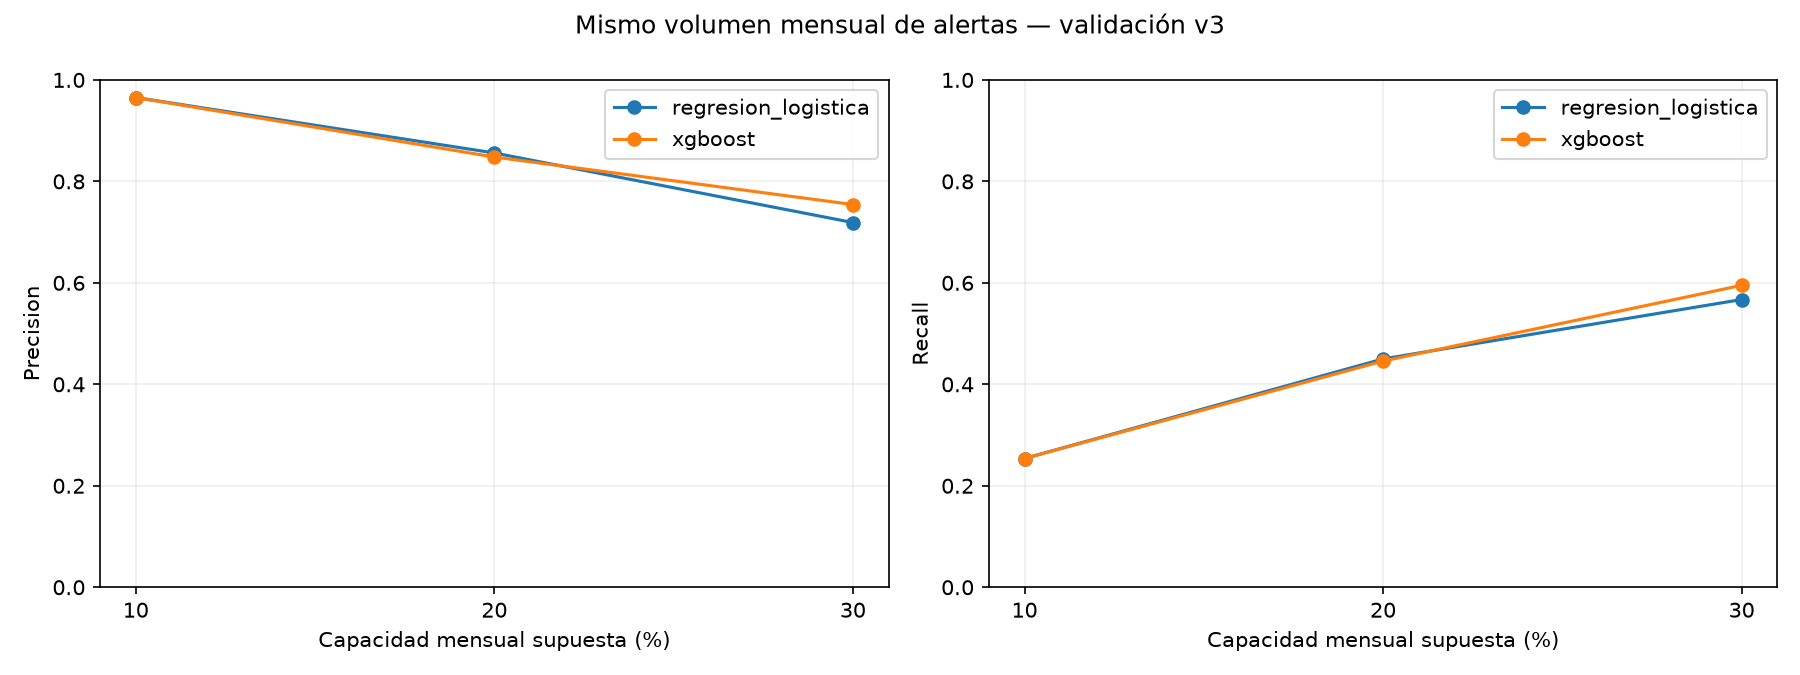

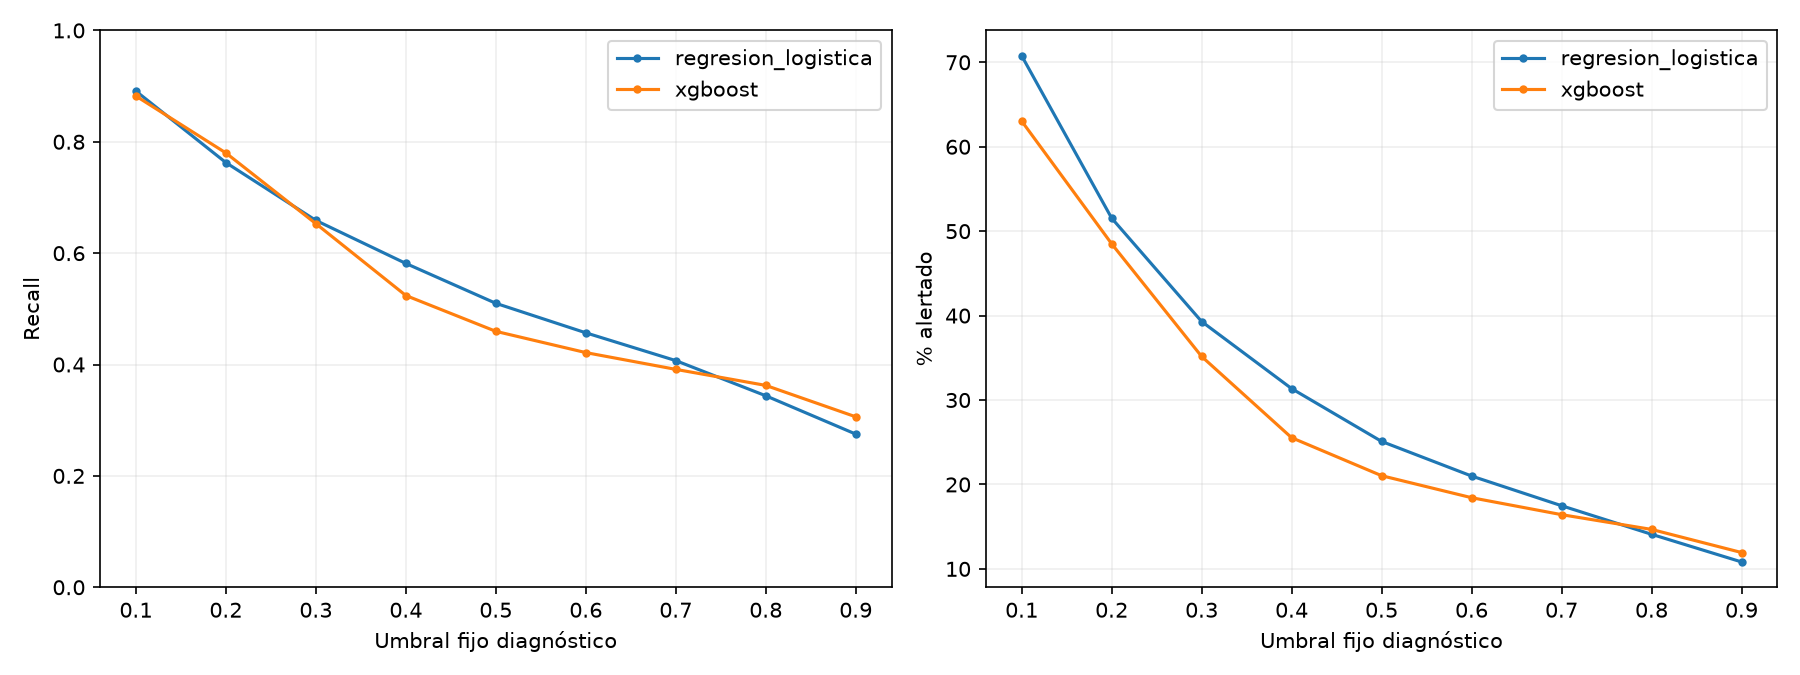

In [2]:
# Contrastar umbrales y capacidad igual, distinguiendo ranking y clasificación fija.
display(tables["umbrales"].round(5))
display(tables["capacidades"].round(5))
display(tables["bordes_empates"].query("capacidad_pct == 20"))
for name in ["capacidades","umbrales"]:
 display(Image(filename=str(ROOT/f"reports/figures/seleccion_8_{name}.png")))

## 3. Calibración

Brier y diez bins fijos se calculan solo en validación v3. Menor Brier no equivale a mejor calibración aislada, pues también recoge resolución. Se comparan probabilidades medias y prevalencia. No se ajusta calibrador. Un mapeo estrictamente creciente conserva orden y empates; uno solo no decreciente puede crear empates y alterar la selección tras el desempate. La política de ranking no necesita probabilidades calibradas para ordenar, pero no permite interpretar scores como frecuencias fiables. El artefacto conserva las salidas originales.

**Qué se hace y por qué.** Describir calibración sin ajustar y evaluar un calibrador sobre las mismas filas.

Brier mide error cuadrático de scores. Un ranking útil no garantiza probabilidades calibradas. No se entrena un calibrador para evaluarlo sobre las mismas observaciones.



,modelo,brier,probabilidad_media,tasa_observada,brecha_media,ece_10_bins_descriptivo
0,regresion_logistica,0.172380,0.330992,0.380192,-0.049200,0.069063
1,xgboost,0.165107,0.303520,0.380192,-0.076672,0.087668


,modelo,bin,limite_inferior,limite_superior,n,probabilidad_media,tasa_observada
0,regresion_logistica,0,0.0,0.1,5818,0.05241,0.14180
1,regresion_logistica,1,0.1,0.2,3830,0.14480,0.25379
2,regresion_logistica,2,0.2,0.3,2438,0.24398,0.32240
3,regresion_logistica,3,0.3,0.4,1582,0.34684,0.36979
4,regresion_logistica,4,0.4,0.5,1246,0.44671,0.43499
5,regresion_logistica,5,0.5,0.6,816,0.54732,0.49142
6,regresion_logistica,6,0.6,0.7,700,0.64584,0.54000
7,regresion_logistica,7,0.7,0.8,674,0.75154,0.70920
8,regresion_logistica,8,0.8,0.9,652,0.85262,0.79908
9,regresion_logistica,9,0.9,1.0,2155,0.96037,0.96613


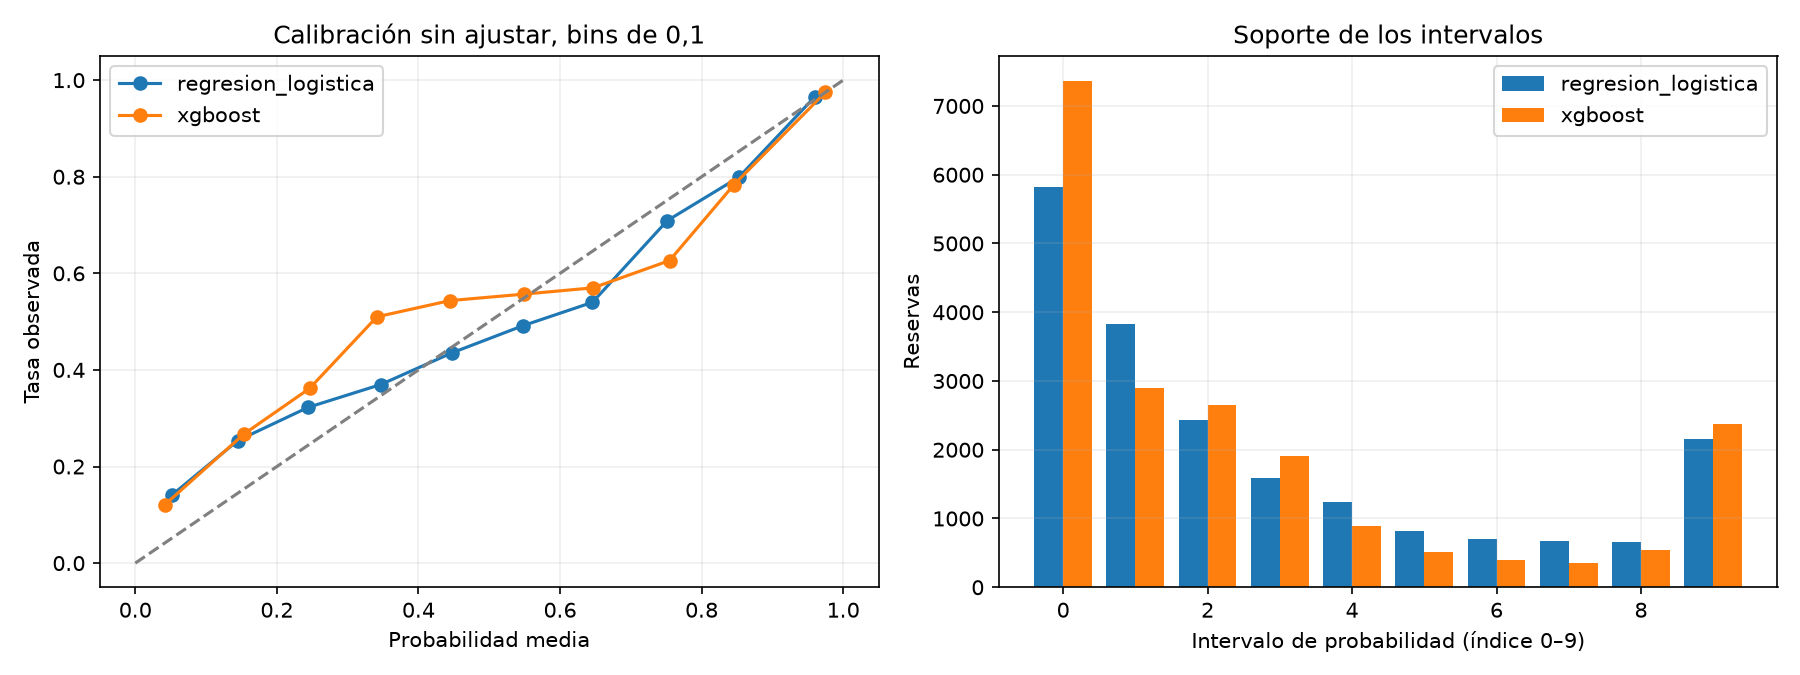

In [3]:
# Describir calibración sin ajustar y evaluar un calibrador sobre las mismas filas.
display(tables["calibracion"].round(6))
display(tables["calibracion_bins"].round(5))
display(Image(filename=str(ROOT/"reports/figures/seleccion_8_calibracion.png")))

## 4. Elección y estabilidad

Se conserva **regresión logística inicial + top 20% mensual**. Con igual volumen detecta 32 cancelaciones más que XGBoost al 20%, con menor complejidad; diferencia descriptiva pequeña, sin superioridad estadística acreditada. XGBoost tiene mayor AUC/AP y mejor Brier, y es mejor al 30%; no se cambia la capacidad para favorecer un candidato. Al 10% ambos tienen los mismos conteos, sin que eso implique seleccionar exactamente las mismas reservas.

Se muestran resultados por mes y hotel de la política mensual. La mejora observada no garantiza beneficio: no hay costes ni eficacia de intervención medidos. La alerta prioriza seguimiento humano, sin sanciones o cancelaciones automáticas.

**Qué se hace y por qué.** Mostrar la única política seleccionada y sus resultados por mes y hotel en validación.

La cuota es conjunta, por lo que City y Resort pueden recibir porcentajes diferentes. Se requiere el lote mensual completo y el 20% es un supuesto académico, no una capacidad real acreditada.



In [4]:
# Mostrar la única política seleccionada y sus resultados por mes y hotel en validación.
display(tables["mensual_capacidad_20"].round(5))
display(tables["hoteles_capacidad_20"].round(5))
print("Modelo:",specification["modelo_seleccionado"])
print("Política:",specification["politica"])
print("Especificación congelada: reports/seleccion_8_especificacion_congelada.json")

,modelo,mes_llegada,n,tasa_cancelacion,precision,recall,f1,fp,fn,tp,tn,alertas,porcentaje_alertado
0,regresion_logistica,2016-09,5394,0.37486,0.88219,0.47033,0.61355,127,1071,951,3245,1078,19.98517
1,regresion_logistica,2016-10,6203,0.40529,0.90242,0.44511,0.59616,121,1395,1119,3568,1240,19.99033
2,regresion_logistica,2016-11,4454,0.36731,0.86404,0.47005,0.60887,121,867,769,2697,890,19.98204
3,regresion_logistica,2016-12,3860,0.36218,0.73575,0.40629,0.52350,204,830,568,2258,772,20.00000
4,xgboost,2016-09,5394,0.37486,0.88868,0.47379,0.61806,120,1064,958,3252,1078,19.98517
5,xgboost,2016-10,6203,0.40529,0.89355,0.44073,0.59030,132,1406,1108,3557,1240,19.99033
6,xgboost,2016-11,4454,0.36731,0.86742,0.47188,0.61124,118,864,772,2700,890,19.98204
7,xgboost,2016-12,3860,0.36218,0.69560,0.38412,0.49493,235,861,537,2227,772,20.00000


,modelo,hotel,n,tasa_cancelacion,precision,recall,f1,fp,fn,tp,tn,alertas,porcentaje_alertado
0,regresion_logistica,City Hotel,13690,0.43433,0.84936,0.47982,0.61322,506,3093,2853,7238,3359,24.53616
1,regresion_logistica,Resort Hotel,6221,0.26105,0.89211,0.34113,0.49354,67,1070,554,4530,621,9.98232
2,xgboost,City Hotel,13690,0.43433,0.86742,0.45442,0.59640,413,3244,2702,7331,3115,22.75383
3,xgboost,Resort Hotel,6221,0.26105,0.77803,0.41441,0.54078,192,951,673,4405,865,13.90452


Modelo: regresion_logistica
Política: {'tipo': 'top_capacidad_mensual', 'version_algoritmo': 1, 'capacidad_pct': 20, 'clave_grupo': 'mes_llegada_YYYY-MM', 'ambito_hoteles': 'ambos hoteles juntos; sin cuotas por hotel', 'fraccion_redondeo': 'floor', 'formula_k': 'n_del_mes * 20 // 100', 'seed_desempate': 42, 'desempate': 'score_desc_sha256(seed|ID)_asc_ID_asc_sin_redondear_score', 'unidad_id': 'meta_row_id entero único del CSV original; orden de entrada no afecta selección', 'score': 'predict_proba[:, clase 1], float64 sin calibrador ni redondeo', 'lote': 'mes calendario completo de llegada; retrospectivo, no cola online', 'umbral_fijo': None, 'accion': 'priorizar seguimiento preventivo humano, sin penalizaciones automáticas'}
Especificación congelada: reports/seleccion_8_especificacion_congelada.json


## 5. Congelación y verificación

Se guarda pipeline ya ajustado solo con train, sin refit con validación. JSON fija versión v3, 14 predictores, transformaciones, parámetros, seed, entorno, huellas, modelo serializado y regla completa de prioridad mensual. Para evaluar posteriormente: verificar hashes, cargar ese artefacto, aplicar la misma regla a scores/IDs/meses sin etiquetas y evaluar solo tras autorización. No se elige un nuevo corte con prueba. Las reejecuciones no sobrescriben el modelo o especificación congelados.

Persisten validación reutilizada, exposición previa del bloque reservado, duplicados, estacionalidad y snapshots inciertos. La política requiere lote mensual y supone recursos, no demuestra viabilidad operativa real. Fin exclusivo de fase 8.

**Qué se hace y por qué.** Verificar las decisiones y los artefactos protegidos de la selección.



In [5]:
# Verificar las decisiones y los artefactos protegidos de la selección.
import io,unittest
from src.comparison import sha
log=io.StringIO()
# Ejecutar la batería indicada y conservar su salida; comprobar qué pruebas admite esta fase.
result=unittest.TextTestRunner(stream=log).run(unittest.defaultTestLoader.discover(str(ROOT/"tests")))
print(log.getvalue())
assert result.wasSuccessful()
for path,expected in verification["archivos_previos_intactos"].items(): assert sha(ROOT/path)==expected,path
assert verification["prueba_transformada_predicha_evaluada"] is False
# La huella debe conservarse: cualquier cambio de datos o evidencia detiene la comprobación.
assert sha(ROOT/"reports/seleccion_8_especificacion_congelada.json")==verification["especificacion_sha256"]
print("Pruebas superadas:",result.testsRun)
print("Prueba sigue sin evaluar. Fin de fase 8.")

C:\Users\panio\Documents\Curso\DataScience\proyecto_machineLearning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


..........................................
----------------------------------------------------------------------
Ran 42 tests in 0.580s

OK

Pruebas superadas: 42
Prueba sigue sin evaluar. Fin de fase 8.
